# Mathematical Modelling Group Project (MAC F314)

## Neuronal firing and excitability with the FitzHugh–Nagumo model

**Goal.** Explain how the same two equations produce rest, one spike, or repeated firing. Then find where the equilibrium changes stability and measure how recovery affects the time between spikes.

**Before you start.** You only need to know what a slope is and how to read an $x$–$y$ graph. Run the cells in order. The colored algorithm blocks describe what the Python cells will do.

1. Work out which way voltage and recovery move at one point.
2. Find the state where both variables can stay still.
3. Simulate a small nudge, a larger nudge, and a sustained current.
4. Read the phase portraits and classify the equilibria.
5. Sweep current, check the two candidate Hopf points, and measure recovery sensitivity.

The FitzHugh–Nagumo model represents the voltage of an excitable cell and a slower recovery process. Here $v$ is voltage, $w$ is recovery, and $I$ is applied current. The time, state and current use scaled model units. A sharp voltage peak represents a spike-like response. [FitzHugh’s original paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC1366333/)

## 🟦 1. Turn the equations into a Python function

$$
\frac{dv}{dt} = v-\frac{v^3}{3}-w+I,
\qquad
\frac{dw}{dt} = \varepsilon(v+a-bw).
$$

Each equation gives the **slope at the current point**. A positive slope means the variable is rising, and a negative slope means it is falling. Increasing $w$ lowers the voltage slope through the $-w$ term. We use $a=0.7$, $b=0.8$, and $\varepsilon=0.08$ so recovery changes on a slower timescale.

At $v=w=0$ and $I=0.5$, the voltage slope is $0.5$ and the recovery slope is $0.08(0.7)=0.056$. The next cell computes both values.

<pre style="background-color: #E7F1FF; color: #17365D; padding: 12px; border-left: 4px solid #2563EB;"><code>MODEL
Read the current voltage v and recovery state w.
Use the two equations to compute their slopes.
Return the voltage slope and the recovery slope.</code></pre>

In [1]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import bisect

a, b, epsilon = 0.7, 0.8, 0.08

def fhn(t, state, current, recovery_rate=epsilon):
    # solve_ivp supplies time t. The current is constant in each experiment.
    v, w = state
    dv_dt = v - v**3 / 3 - w + current
    dw_dt = recovery_rate * (v + a - b * w)
    return dv_dt, dw_dt

voltage_slope, recovery_slope = fhn(0, (0, 0), 0.5)
print(f"At v = w = 0 and I = 0.5: dv/dt = {voltage_slope:.3f}, dw/dt = {recovery_slope:.3f}")
assert abs(voltage_slope - 0.5) < 1e-12
assert abs(recovery_slope - 0.056) < 1e-12

At v = w = 0 and I = 0.5: dv/dt = 0.500, dw/dt = 0.056


## 🟩 2. Find the resting state at zero current

At an **equilibrium**, both slopes are zero. Setting the voltage slope to zero gives $w=v-v^3/3+I$. Setting the recovery slope to zero gives $w=(v+a)/b$. These two curves are called **nullclines**. Their intersection gives the equilibrium.

Substituting the second expression into the first gives

$$
\frac{b}{3}v_*^3+(1-b)v_*+a-bI=0.
$$

We first search for the root at $I=0$. Later we use the same calculation at other currents. **Bisection** repeatedly halves an interval whose endpoints have opposite signs. Each step keeps the half containing the sign change. At our chosen $b$, the cubic is strictly increasing, so the root is unique.

<pre style="background-color: #E8F7ED; color: #15432B; padding: 12px; border-left: 4px solid #27804E;"><code>REST
Find the voltage where the cubic is zero at I = 0.
Use that voltage to compute the recovery state.
Substitute both values into the original slope equations.</code></pre>

In [2]:
def equilibrium_cubic(v, current):
    return (b / 3) * v**3 + (1 - b) * v + a - b * current

def equilibrium(current):
    # The bracket [-3, 3] contains the root for the currents in this notebook.
    v_star = bisect(equilibrium_cubic, -3.0, 3.0, args=(current,))
    return v_star, (v_star + a) / b

rest_v, rest_w = equilibrium(0.0)

# Both slopes must be essentially zero at an equilibrium.
assert all(abs(slope) < 1e-10 for slope in fhn(0, (rest_v, rest_w), 0.0))
print(f"Zero-current equilibrium: v = {rest_v:.4f}, w = {rest_w:.4f}")

Zero-current equilibrium: v = -1.1994, w = -0.6243


## 🟨 3. Run three experiments

The solver uses the slopes to estimate how $v$ and $w$ change over time. We ask it to report 1,501 points from time 0 to 150. The solver uses an adaptive Runge–Kutta method. It estimates the state at the end of each step from several slope evaluations and adjusts its step size to control error. The output times are where we ask it to report the solution. [SciPy’s integration guide](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)

| Run | Initial voltage | Applied current |
| --- | --- | --- |
| Small nudge | Resting voltage plus $0.05$ | $I=0$ throughout |
| Larger nudge | Resting voltage plus $0.90$ | $I=0$ throughout |
| Sustained input | Same starting voltage as the small nudge | $I=0.50$ throughout |

In all three runs, recovery starts at the same value $w_*$. The nudges are changes to the initial voltage. The current in the third run stays on for the full simulation.

<pre style="background-color: #FFF3D4; color: #503300; padding: 12px; border-left: 4px solid #B56A00;"><code>SIMULATE
Choose the starting voltage and the constant current.
Start recovery at its zero-current equilibrium value.
Integrate the two equations and keep the resulting voltage curve.</code></pre>

In [3]:
times = [step / 10 for step in range(1501)]

def simulate(initial_state, current, sample_times, *, recovery_rate=epsilon, rtol=1e-9, atol=1e-11):
    # args keeps the current and recovery rate fixed throughout one run.
    solution = solve_ivp(
        fhn,
        (sample_times[0], sample_times[-1]),
        initial_state,
        args=(current, recovery_rate),
        t_eval=sample_times,
        method="DOP853",
        rtol=rtol,
        atol=atol,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    # Row 0 is voltage, and row 1 is recovery.
    return solution.y

near_rest = (rest_v + 0.05, rest_w)
far_from_rest = (rest_v + 0.90, rest_w)

small_nudge = simulate(near_rest, 0.0, times)
large_nudge = simulate(far_from_rest, 0.0, times)
sustained = simulate(near_rest, 0.50, times)

## 🟪 4. Plot the responses on the same scale

All three plots use the same vertical scale so their voltage peaks can be compared directly. The right panel also shows the slower recovery curve in gray. The dashed line marks the **zero-current resting voltage**, which is a reference for the two nudge experiments.

<pre style="background-color: #F1EAFE; color: #38205C; padding: 12px; border-left: 4px solid #7547B2;"><code>COMPARE
Plot time along the bottom and voltage up the side.
Use the same axis limits for each experiment.
Look for a return to rest, one spike, and repeated spikes.</code></pre>

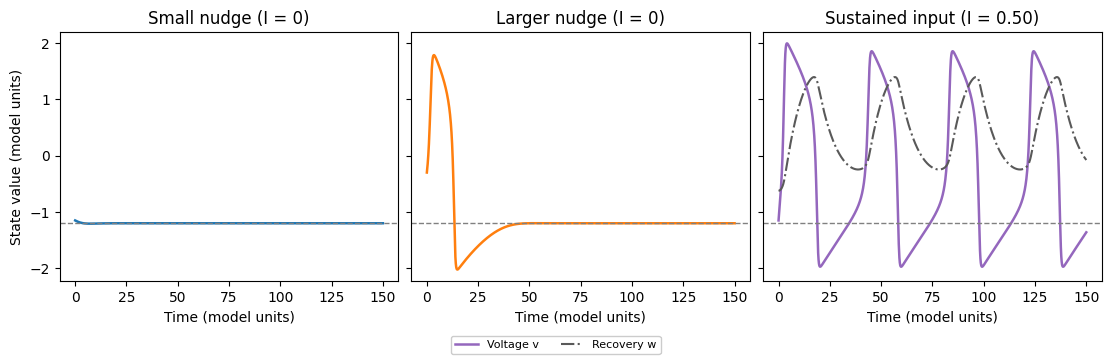

In [4]:
response_figure, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True, sharey=True, layout="constrained")
traces = [
    (small_nudge[0], "Small nudge (I = 0)", "tab:blue"),
    (large_nudge[0], "Larger nudge (I = 0)", "tab:orange"),
    (sustained[0], "Sustained input (I = 0.50)", "tab:purple"),
]

for ax, (voltage, title, color) in zip(axes, traces):
    # Shared axes make the three spike heights directly comparable.
    ax.plot(times, voltage, color=color, linewidth=1.8, label="Voltage v")
    ax.axhline(rest_v, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Time (model units)")

axes[2].plot(times, sustained[1], color="0.35", linestyle="-.", label="Recovery w")
handles, labels = axes[2].get_legend_handles_labels()
response_figure.legend(handles, labels, loc="outside lower center", ncols=2, fontsize=8, framealpha=1)
axes[0].set_ylabel("State value (model units)")
plt.show()

**Reading the plots.** The small nudge fades. The larger nudge produces a single spike and still returns to the same resting level. With current kept on, the model produces repeated spikes. The plot on the right is a starting point for studying how the long-term behaviour changes as we vary $I$.

## 🟧 5. Check the result

For these particular traces, count a spike when voltage crosses zero **upward**. Estimate the crossing time by drawing a straight line between the samples on either side of zero. Check that the two zero-current runs return to rest and that the firing result persists when we tighten the solver tolerances.

<pre style="background-color: #FFEDE3; color: #522915; padding: 12px; border-left: 4px solid #B55223;"><code>VERIFY
Count upward crossings of zero.
Check that the two nudges return to the resting voltage.
Repeat the sustained-current run with tighter tolerances.</code></pre>

In [5]:
def spike_times(sample_times, voltage):
    crossings = []
    for left_t, right_t, left_v, right_v in zip(
        sample_times, sample_times[1:], voltage, voltage[1:]
    ):
        if left_v < 0 <= right_v:
            # Interpolate where the voltage crosses zero between two samples.
            fraction = -left_v / (right_v - left_v)
            crossings.append(left_t + fraction * (right_t - left_t))
    return crossings

counts = [len(spike_times(times, trace[0])) for trace in (small_nudge, large_nudge, sustained)]
assert counts == [0, 1, 4]
assert abs(small_nudge[0, -1] - rest_v) < 1e-6
assert abs(large_nudge[0, -1] - rest_v) < 1e-6

# Compare both state variables on the same output grid.
tighter = simulate(near_rest, 0.50, times, rtol=1e-11, atol=1e-13)
largest_difference = abs(sustained - tighter).max()
assert largest_difference < 1e-6
print(f"Spike counts: {', '.join(str(count) for count in counts)}")
print(f"Numerical checks passed. Largest change with tighter tolerances: {largest_difference:.2e}")

Spike counts: 0, 1, 4
Numerical checks passed. Largest change with tighter tolerances: 4.39e-08


## 🟦 6. Draw the phase portraits

A **phase plane** puts voltage $v$ on the horizontal axis and recovery $w$ on the vertical axis. A point represents the neuron's state at one instant. Time is represented by motion along a path.

- An arrow shows which way the state moves. A positive voltage slope points to the right. A positive recovery slope points up.
- On the voltage nullcline, arrows point vertically because voltage is momentarily flat. On the recovery nullcline, arrows point horizontally.
- At their intersection, both slopes are zero. The state stays still if it starts exactly there.

We plot the zero-current excursion and the sustained-current trajectory. The arrows are scaled to similar lengths so their **direction** is easier to read.

<pre style="background-color: #DCF6FA; color: #16424C; padding: 12px; border-left: 4px solid #16869A;"><code>PHASE PLANE
Choose a grid of voltage and recovery values.
Evaluate both slopes at each point and draw an arrow.
Draw the two nullclines and mark their intersection.
Plot voltage against recovery for a simulated trajectory.</code></pre>

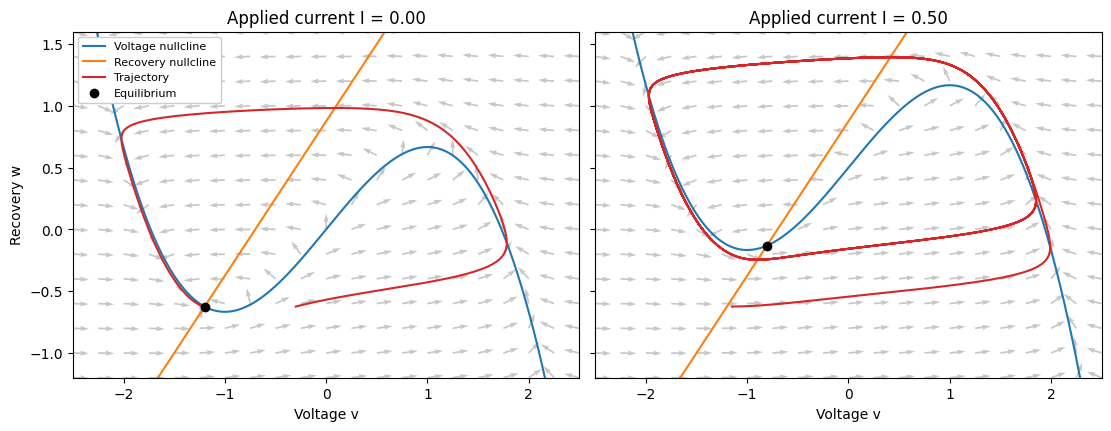

In [6]:
voltage_grid = [step / 4 for step in range(-10, 11)]
recovery_grid = [step / 5 for step in range(-6, 9)]
voltage_line = [step / 100 for step in range(-250, 251)]

phase_figure, phase_axes = plt.subplots(
    1, 2, figsize=(11, 4.2), sharey=True, layout="constrained"
)
for ax, current, trajectory in zip(phase_axes, (0.0, 0.50), (large_nudge, sustained)):
    grid_v, grid_w, arrows_v, arrows_w = [], [], [], []
    for w in recovery_grid:
        for v in voltage_grid:
            dv, dw = fhn(0, (v, w), current)
            # Rescale the arrow without changing its direction.
            length = max((dv**2 + dw**2)**0.5, 1e-12)
            grid_v.append(v)
            grid_w.append(w)
            arrows_v.append(dv / length)
            arrows_w.append(dw / length)

    ax.quiver(grid_v, grid_w, arrows_v, arrows_w, color="0.78", angles="xy")
    ax.plot(voltage_line, [v - v**3 / 3 + current for v in voltage_line], label="Voltage nullcline")
    ax.plot(voltage_line, [(v + a) / b for v in voltage_line], label="Recovery nullcline")
    ax.plot(trajectory[0], trajectory[1], color="tab:red", label="Trajectory")
    ax.scatter(*equilibrium(current), color="black", marker="o", zorder=5, label="Equilibrium")
    ax.set(title=f"Applied current I = {current:.2f}", xlabel="Voltage v",
           xlim=(-2.5, 2.5), ylim=(-1.2, 1.6))

phase_axes[0].set_ylabel("Recovery w")
phase_axes[0].legend(loc="upper left", framealpha=1, fontsize=8)
plt.show()

**Reading the phase portraits.** At zero current the trajectory makes one large excursion and comes back to the equilibrium. At $I=0.50$ the trajectory settles into a repeating loop. Each trip around the loop corresponds to one firing cycle. The graph still has an equilibrium at the nullcline intersection, so we need a stability test to explain why nearby states move away from it.

## 🟪 7. Read stability from the Jacobian

**Local stability** asks what happens after a very small nudge from equilibrium. The Jacobian describes how the slopes respond to small changes in voltage and recovery. Its rows correspond to $dv/dt$ and $dw/dt$. Its columns correspond to changing $v$ and changing $w$.

$$
J(v_*) =
egin{pmatrix}
1-v_*^2 & -1 \\
\varepsilon & -\varepsilon b
\end{pmatrix}.
$$

For example, the top-right entry is $-1$ because the voltage equation contains $-w$. The trace $T$ is the sum of the diagonal entries. The determinant $D$ is the product along the main diagonal minus the product along the other diagonal.

$$
T=1-v_*^2-\varepsilon b,
\qquad D=\varepsilon\bigl[1-b(1-v_*^2)\bigr].
$$

The eigenvalues are the two roots of $\lambda^2-T\lambda+D=0$. Their **real parts** describe whether small disturbances shrink or grow. If both real parts are negative, disturbances decay. If one is positive, the equilibrium is unstable. A real part close to zero calls for more analysis.

<pre style="background-color: #F5E8F3; color: #49213E; padding: 12px; border-left: 4px solid #994283;"><code>STABILITY
Find the equilibrium at the selected current.
Evaluate the Jacobian and compute its trace and determinant.
Use the quadratic formula and inspect both real parts.
Simulate a small nudge and compare the distance from equilibrium.</code></pre>

To check the prediction, start $0.01$ voltage units away from each equilibrium and simulate to time 150. Compare the final distance in the phase plane with the starting distance of $0.01$.

In [7]:
def jacobian(v):
    return (1 - v**2, -1), (epsilon, -epsilon * b)

def trace_and_determinant(v):
    (j11, j12), (j21, j22) = jacobian(v)
    return j11 + j22, j11 * j22 - j12 * j21

def eigenvalues(v):
    trace, determinant = trace_and_determinant(v)
    discriminant = trace**2 - 4 * determinant
    # A negative discriminant gives an imaginary square root.
    root = discriminant**0.5 if discriminant >= 0 else complex(0, (-discriminant)**0.5)
    return (trace + root) / 2, (trace - root) / 2

def largest_real_part(v):
    return max(value.real for value in eigenvalues(v))

print(f"{'I':>5}  {'v*':>9}  {'w*':>9}  {'Eigenvalues':>36}  {'Distance at t=150':>17}  Stability")
for current in (0.0, 0.50, 1.60):
    v_star, w_star = equilibrium(current)
    assert all(abs(slope) < 1e-10 for slope in fhn(0, (v_star, w_star), current))
    first, second = eigenvalues(v_star)
    rate = max(first.real, second.real)
    if rate < -1e-8:
        label = "stable"
    elif rate > 1e-8:
        label = "unstable"
    else:
        label = "linear test inconclusive"

    # Compare the final state with the same equilibrium we nudged away from.
    voltage, recovery = simulate((v_star + 0.01, w_star), current, [0.0, 150.0])
    distance = ((voltage[-1] - v_star)**2 + (recovery[-1] - w_star)**2)**0.5
    if rate < -1e-8:
        assert distance < 0.01
    elif rate > 1e-8:
        assert distance > 0.01
    print(f"{current:5.2f}  {v_star:9.4f}  {w_star:9.4f}  "
          f"{first:>17.4f}, {second:>17.4f}  {distance:17.2e}  {label}")

assert largest_real_part(rest_v) < 0
assert largest_real_part(equilibrium(0.50)[0]) > 0

    I         v*         w*                           Eigenvalues  Distance at t=150  Stability
 0.00    -1.1994    -0.6243    -0.2513+0.2119j,   -0.2513-0.2119j           2.51e-10  stable
 0.50    -0.8048    -0.1311     0.1441+0.1915j,    0.1441-0.1915j           1.70e+00  unstable
 1.60     1.1043     2.2554    -0.1418+0.2719j,   -0.1418-0.2719j           1.41e-11  stable


**Interpretation.** The equilibrium is locally stable at $I=0$, unstable at $I=0.50$, and stable again at $I=1.60$. The distance from equilibrium shrinks in the stable cases and grows in the unstable case. The earlier large-nudge experiment shows that a trajectory can travel far from a stable equilibrium before returning to it.

## 🟨 8. Sweep the applied current

A **bifurcation** is a change in the type of behaviour when a setting varies. Here we vary the applied current and keep $a$, $b$, and $\varepsilon$ fixed. Each value of $I$ gets its own simulation from the same starting state.

The first graph compares the equilibrium voltage with the minimum and maximum voltage from time 300 to 600. When the minimum and maximum nearly coincide with the equilibrium, that run has nearly settled. A large separation shows that the voltage is still varying. The second graph shows where the equilibrium's largest eigenvalue real part changes sign. The two graphs answer different questions about the simulated path and the equilibrium.

<pre style="background-color: #F8F1DC; color: #4F3811; padding: 12px; border-left: 4px solid #9A6D17;"><code>CURRENT SWEEP
Increase the current in small steps across separate simulations.
At each step, calculate the equilibrium and its largest eigenvalue real part.
Record the smallest and largest voltage after time 300.
Plot both summaries against current.</code></pre>

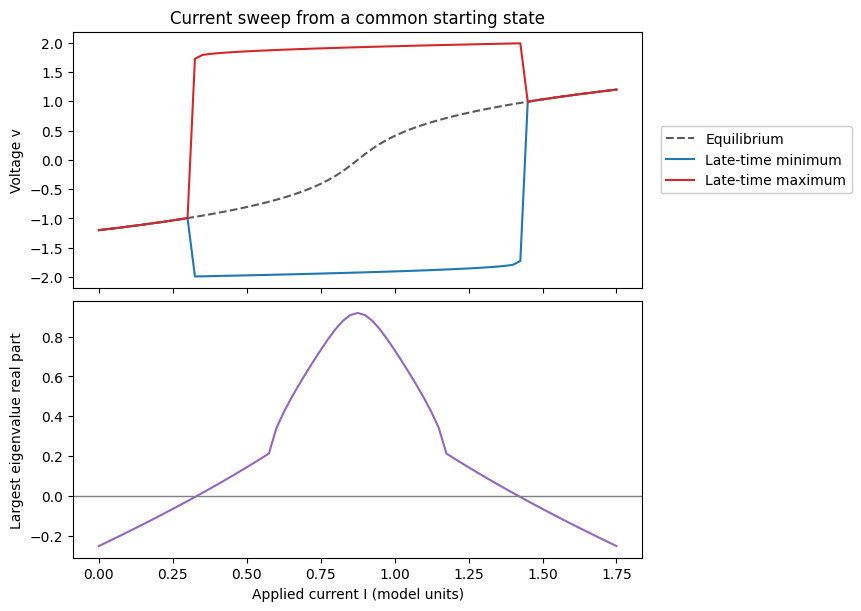

In [8]:
currents = [step / 40 for step in range(71)]
late_times = [0.0] + [300 + step / 5 for step in range(1501)]
equilibrium_voltages, real_parts = [], []
minimum_voltages, maximum_voltages = [], []

for current in currents:
    v_star, _ = equilibrium(current)
    equilibrium_voltages.append(v_star)
    real_parts.append(largest_real_part(v_star))
    # Keep time zero for the initial state, then take extrema only in the late window.
    late_voltage = simulate(near_rest, current, late_times)[0, 1:]
    minimum_voltages.append(late_voltage.min())
    maximum_voltages.append(late_voltage.max())

sweep_figure, sweep_axes = plt.subplots(2, 1, figsize=(8.5, 6.0), sharex=True, layout="constrained")
voltage_ax, stability_ax = sweep_axes
voltage_ax.plot(currents, equilibrium_voltages, color="0.35", linestyle="--", label="Equilibrium")
voltage_ax.plot(currents, minimum_voltages, color="tab:blue", label="Late-time minimum")
voltage_ax.plot(currents, maximum_voltages, color="tab:red", label="Late-time maximum")
voltage_ax.set(title="Current sweep from a common starting state", ylabel="Voltage v")
voltage_ax.legend(framealpha=1, loc="center left", bbox_to_anchor=(1.02, 0.5))

stability_ax.plot(currents, real_parts, color="tab:purple")
stability_ax.axhline(0, color="0.5", linewidth=1)
stability_ax.set(xlabel="Applied current I (model units)", ylabel="Largest eigenvalue real part")
plt.show()

## 🟧 9. Check the two Hopf points

A **Hopf bifurcation** can occur when a pair of complex eigenvalues passes through the imaginary axis as current changes. In two dimensions, the eigenvalues are purely imaginary when $T=0$ and $D>0$. Solving $T=0$ gives two candidate voltages. Substituting each one into the equilibrium relation gives its current.

$$
v_H=\pm\sqrt{1-\varepsilon b},
\qquad
I_H=\frac{v_H+a}{b}-v_H+\frac{v_H^3}{3}.
$$

We check that the determinant is positive and that the eigenvalue real part changes sign across each candidate. The trace crosses at a nonzero rate because $dT/dI=-2bv_H/(bv_H^2+1-b)$ at the candidate. A complete classification of the Hopf bifurcation would also require a nonlinear calculation, such as the first Lyapunov coefficient. [Kuznetsov’s overview of Hopf bifurcation](https://doi.org/10.4249/scholarpedia.1858)

To check how the simulations behave near each crossing, use a finer current offset and a later observation window. Compare a small voltage nudge with a larger nudge toward the middle of the voltage range. A finite set of runs can miss other long-term behaviours. A wide voltage span in the table shows that the run was still varying over that window.

<pre style="background-color: #FCE8DD; color: #592D21; padding: 12px; border-left: 4px solid #B55432;"><code>HOPF CHECK
Solve the trace equation and convert each candidate voltage to a current.
Check that the determinant is positive and the real part crosses zero.
Compare late-time voltage spans on both sides using two initial states.</code></pre>

In [9]:
hopf_magnitude = (1 - epsilon * b)**0.5
offset = 0.004
refined_times = [0.0] + [1700 + step / 5 for step in range(1501)]

for v_h in (-hopf_magnitude, hopf_magnitude):
    current_h = (v_h + a) / b - v_h + v_h**3 / 3
    trace, determinant = trace_and_determinant(v_h)
    trace_slope = -2 * b * v_h / (b * v_h**2 + 1 - b)
    left_rate = largest_real_part(equilibrium(current_h - offset)[0])
    right_rate = largest_real_part(equilibrium(current_h + offset)[0])
    assert abs(trace) < 1e-12 and determinant > 0
    assert trace_slope != 0 and left_rate * right_rate < 0

    print(f"Candidate I = {current_h:.6f}: determinant = {determinant:.6f}, trace slope = {trace_slope:+.3f}")
    print(f"  {'I':>9}  {'Max Re':>9}  {'Small nudge span':>17}  {'Larger nudge span':>18}")
    for current in (current_h - offset, current_h + offset):
        v_star, w_star = equilibrium(current)
        direction = 1 if v_h < 0 else -1
        spans = []
        for nudge in (0.01, 0.80):
            # Nudge toward the middle of the voltage range at each boundary.
            initial_state = (v_star + direction * nudge, w_star)
            late_voltage = simulate(initial_state, current, refined_times)[0, 1:]
            spans.append(late_voltage.max() - late_voltage.min())
        print(f"  {current:9.6f}  {largest_real_part(v_star):+9.5f}  {spans[0]:17.5f}  {spans[1]:18.5f}")

Candidate I = 0.331281: determinant = 0.075904, trace slope = +1.631
          I     Max Re   Small nudge span   Larger nudge span
   0.327281   -0.00326            0.00008             3.73783


   0.335281   +0.00327            3.76057             3.76057
Candidate I = 1.418719: determinant = 0.075904, trace slope = -1.631
          I     Max Re   Small nudge span   Larger nudge span


   1.414719   +0.00327            3.76057             3.76057


   1.422719   -0.00326            0.00008             3.73783


**Interpretation.** The equilibrium loses stability near $I=0.331$ and regains it near $I=1.419$. Just outside that interval, the small nudge nearly settles while the larger nudge keeps oscillating over the recorded window. This is numerical evidence that rest and repeated firing can coexist at the same current for the cases we tested.

## 🟩 10. Measure recovery sensitivity

Sensitivity analysis asks how a result changes when we change one setting. Keep the current at $I=0.50$, keep the same initial state, and change only $\varepsilon$. Compare the **mean period**, the average time between successive spikes. A longer period means slower firing.

Ignore the first 150 time units. Locate upward crossings of zero by the same rule as before, and average the time differences between crossings after the transient.

<pre style="background-color: #E1F5E8; color: #1B452D; padding: 12px; border-left: 4px solid #2C7C50;"><code>SENSITIVITY
Run the model at three recovery rates with the same current.
Discard spikes from the initial transient.
Average the time gaps between the remaining spikes.</code></pre>

 Epsilon   Late spikes   Mean period
    0.06             7        49.157
    0.08             8        39.475


    0.10             9        33.525
Sensitivity checks passed.


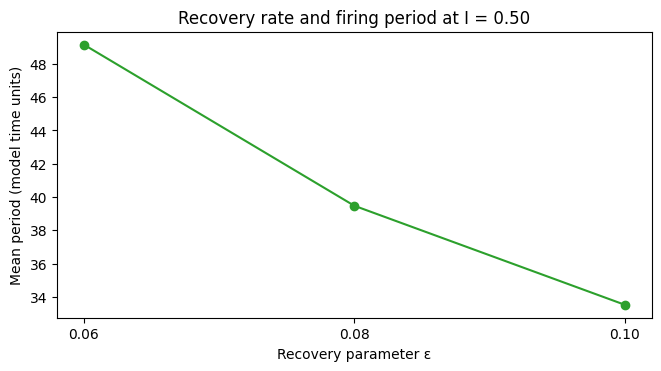

In [10]:
recovery_rates = [0.06, 0.08, 0.10]
sensitivity_times = [step / 10 for step in range(4501)]
mean_periods = []

print(f"{'Epsilon':>8}  {'Late spikes':>12}  {'Mean period':>12}")
for recovery_rate in recovery_rates:
    voltage = simulate(near_rest, 0.50, sensitivity_times, recovery_rate=recovery_rate)[0]
    # Count only crossings inside the late-time measurement window.
    crossings = [time for time in spike_times(sensitivity_times, voltage) if time >= 150]
    assert len(crossings) >= 3
    periods = [later - earlier for earlier, later in zip(crossings, crossings[1:])]
    mean_period = sum(periods) / len(periods)
    mean_periods.append(mean_period)
    print(f"{recovery_rate:8.2f}  {len(crossings):12d}  {mean_period:12.3f}")

assert mean_periods[0] > mean_periods[1] > mean_periods[2]
print("Sensitivity checks passed.")

sensitivity_figure, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
ax.plot(recovery_rates, mean_periods, marker="o", color="tab:green")
ax.set(title="Recovery rate and firing period at I = 0.50",
       xlabel="Recovery parameter ε", ylabel="Mean period (model time units)")
ax.set_xticks(recovery_rates)
plt.show()

**Interpretation.** For the three recovery rates tested at $I=0.50$, increasing $\varepsilon$ shortens the time between spikes. This describes the tested range and current.

## ⬛ 11. Export figures for the report

Set `EXPORT_FIGURES = True` and rerun this cell when you need the report figures. Each figure is saved as a vector PDF for inclusion in Overleaf and an EPS file for submission. Both versions come from the same plot.

<pre style="background-color: #E9EDF4; color: #27344A; padding: 12px; border-left: 4px solid #4A607E;"><code>REPORT FIGURES
Create the report figure folder when export is enabled.
Save each figure once as PDF and once as EPS.</code></pre>

In [11]:
EXPORT_FIGURES = False

if EXPORT_FIGURES:
    # The standard library handles the same output folder on any platform.
    from pathlib import Path

    figure_dir = Path("report") / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    figures = {
        "voltage_responses": response_figure,
        "phase_portraits": phase_figure,
        "current_sweep": sweep_figure,
        "recovery_sensitivity": sensitivity_figure,
    }
    for name, figure in figures.items():
        figure.savefig(figure_dir / f"{name}.pdf")
        figure.savefig(figure_dir / f"{name}.eps")
    print(f"Saved {len(figures)} figures in PDF and EPS to {figure_dir}")

## Conclusions and limitations

- A small disturbance fades, a larger one gives a single excursion, and suitable sustained current gives repeated firing for the chosen model settings.
- The phase portraits and the eigenvalues explain why the zero-current run can return to rest and why the sustained-current run moves away from its equilibrium.
- The current sweep identifies two candidate Hopf points. The simulation summaries depend on the time window and initial conditions, and the local stability calculation describes behaviour near the equilibrium.
- At the tested current, faster recovery gives a shorter mean firing period. The model uses scaled units and captures qualitative behaviour of one excitable cell.

## References

- FitzHugh, R. (1961). [Impulses and Physiological States in Theoretical Models of Nerve Membrane](https://pmc.ncbi.nlm.nih.gov/articles/PMC1366333/).
- Nagumo, J., Arimoto, S., and Yoshizawa, S. (1962). [An Active Pulse Transmission Line Simulating Nerve Axon](https://doi.org/10.1109/JRPROC.1962.288235).
- Kuznetsov, Y. A. (2006). [Andronov–Hopf bifurcation](https://doi.org/10.4249/scholarpedia.1858).
- SciPy. [`solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).

**AI acknowledgment.** OpenAI Codex helped draft the notebook, add explanatory comments, and check the numerical results.